# Lab Task #05 – Spatial Filtering and Convolution

**The University of Azad Jammu and Kashmir – Department of Software Engineering**  
**Digital Image Processing Lab | Instructor:** Engr. Fahad Nisar  
**Semester:** Fifth | **Session:** 2024–28 (SE)

**Student:** Syed Muhammad Hassan Gillani  
**Roll No.:** 2024-SE-42

**Assigned:** November 13, 2026 | **Due:** November 20, 2026, 11:59 PM

## Objective
Implement 2D convolution from first principles and apply mean, Gaussian, and median filters to remove noise from real images. Verify the custom convolution against OpenCV, complete both dry-run calculations, and judge filtered images against their clean originals.

**Requirements:** Python 3, Jupyter Notebook, NumPy, OpenCV, Matplotlib, and scikit-image.

## 1. Import libraries
The required libraries and image datasets are imported below.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data
from skimage.color import rgb2gray
np.set_printoptions(precision=4, suppress=True)
print("NumPy:", np.__version__, "| OpenCV:", cv2.__version__)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-eqk58q21 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


NumPy: 2.3.5 | OpenCV: 4.13.0


## 2. Load test images
Camera and Coins are grayscale. Chelsea is converted from RGB to grayscale. The clean originals are not modified.

Camera shape: (512, 512) dtype: uint8 range: (0, 255)
Coins shape: (303, 384) dtype: uint8 range: (1, 252)
Chelsea (grayscale) shape: (300, 451) dtype: uint8 range: (4, 193)


/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


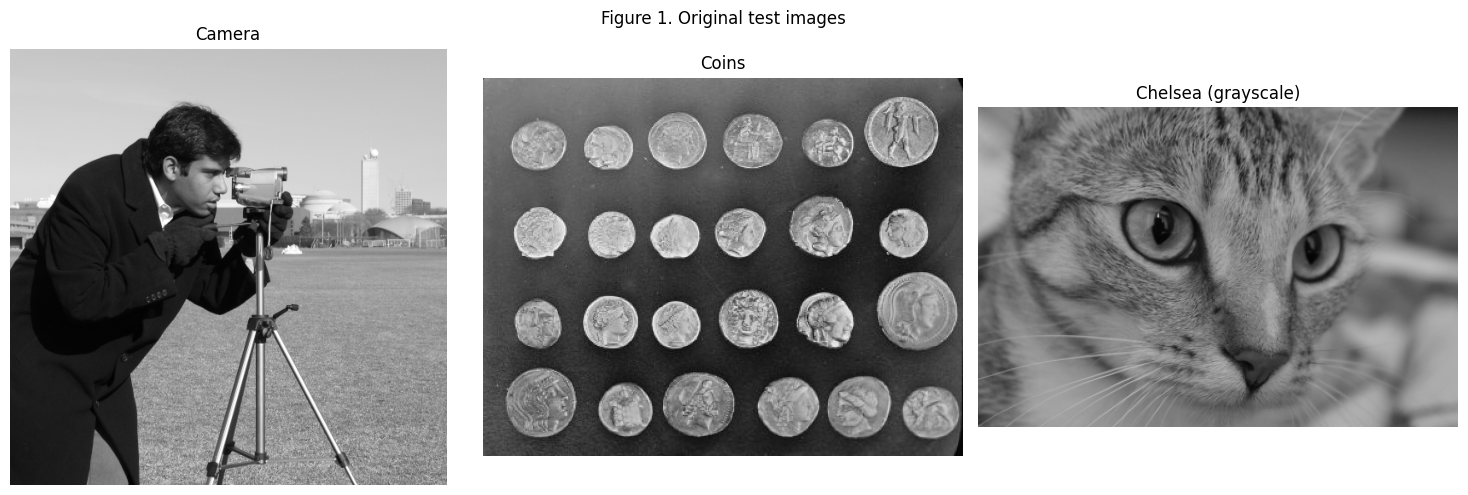

In [2]:
camera_original = data.camera().copy()
coins_original = data.coins().copy()
chelsea_rgb_original = data.chelsea().copy()
chelsea_original = np.rint(rgb2gray(chelsea_rgb_original) * 255).clip(0,255).astype(np.uint8)
clean_images = {"Camera": camera_original, "Coins": coins_original, "Chelsea (grayscale)": chelsea_original}
for name, img in clean_images.items():
    print(name, "shape:", img.shape, "dtype:", img.dtype, "range:", (int(img.min()), int(img.max())))
fig, axes = plt.subplots(1,3,figsize=(15,5))
for ax,(name,img) in zip(axes,clean_images.items()):
    ax.imshow(img,cmap="gray",vmin=0,vmax=255); ax.set_title(name); ax.axis("off")
plt.suptitle("Figure 1. Original test images"); plt.tight_layout(); plt.show()

## 3. Custom 2D convolution – `conv2d_loop`
The function flips the kernel in both dimensions (true convolution), pads with NumPy reflect padding, and uses nested pixel loops. Calculations and the returned array are float64; conversion to uint8 is delayed until the final output.

In [3]:
def conv2d_loop(img, kernel):
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    if img.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image and kernel must be 2D.")
    if kernel.shape[0] % 2 == 0 or kernel.shape[1] % 2 == 0:
        raise ValueError("Kernel dimensions must be odd.")
    flipped = np.flip(kernel, axis=(0,1))
    py, px = kernel.shape[0]//2, kernel.shape[1]//2
    padded = np.pad(img, ((py,py),(px,px)), mode="reflect")
    out = np.zeros(img.shape, dtype=np.float64)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            patch = padded[y:y+kernel.shape[0], x:x+kernel.shape[1]]
            out[y,x] = np.sum(patch * flipped)
    return out

def to_uint8(img):
    return np.rint(img).clip(0,255).astype(np.uint8)

print("Convolution function defined.")

Convolution function defined.


### 3.1 Verify against OpenCV on a real image
OpenCV `filter2D` performs correlation, so the flipped kernel is passed to it to match true convolution. `BORDER_REFLECT_101` matches NumPy reflect padding. An asymmetric Sobel-style kernel makes the flip test meaningful.

In [4]:
test_kernel = np.array([[-1,0,1],[-2,0,2],[-1,0,1]],dtype=np.float64)
ours = conv2d_loop(camera_original, test_kernel)
opencv = cv2.filter2D(camera_original.astype(np.float64), cv2.CV_64F,
                      np.flip(test_kernel,axis=(0,1)), borderType=cv2.BORDER_REFLECT_101)
largest_difference = float(np.max(np.abs(ours-opencv)))
print("Custom dtype:",ours.dtype,"shape:",ours.shape)
print("OpenCV shape:",opencv.shape)
print("Largest absolute difference:",format(largest_difference,".12g"))
print("Numerically equal:",np.allclose(ours,opencv,atol=1e-9))

Custom dtype: float64 shape: (512, 512)
OpenCV shape: (512, 512)
Largest absolute difference: 0
Numerically equal: True


## 4. Custom noise generation (R5)
Both functions use a local random generator with seed 5. Gaussian noise has mean 0 and standard deviation `sigma`. Salt-and-pepper noise changes a reproducible fraction of pixels to 0 or 255.

In [5]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noisy = np.asarray(img,dtype=np.float64) + rng.normal(0,sigma,np.asarray(img).shape)
    return to_uint8(noisy)

def add_salt_pepper(img, amount=0.05, seed=5):
    if not 0 <= amount <= 1:
        raise ValueError("amount must be between 0 and 1")
    result = np.asarray(img).copy()
    rng = np.random.default_rng(seed)
    n = int(round(amount*result.size))
    indices = rng.choice(result.size,size=n,replace=False)
    flat = result.reshape(-1)
    half = n//2
    flat[indices[:half]] = 0
    flat[indices[half:]] = 255
    return result

noisy_images = {}
for name,clean in clean_images.items():
    noisy_images[(name,"Gaussian noise")] = add_gaussian_noise(clean,sigma=20,seed=5)
    noisy_images[(name,"Salt-and-pepper noise")] = add_salt_pepper(clean,amount=0.05,seed=5)

print("Gaussian reproducible:",np.array_equal(noisy_images[("Camera","Gaussian noise")],
      add_gaussian_noise(camera_original,20,5)))
print("Salt-pepper reproducible:",np.array_equal(noisy_images[("Camera","Salt-and-pepper noise")],
      add_salt_pepper(camera_original,0.05,5)))

Gaussian reproducible: True
Salt-pepper reproducible: True


### 4.1 Original and noisy image grid
This grid shows each clean image beside its Gaussian-noise and salt-and-pepper versions.

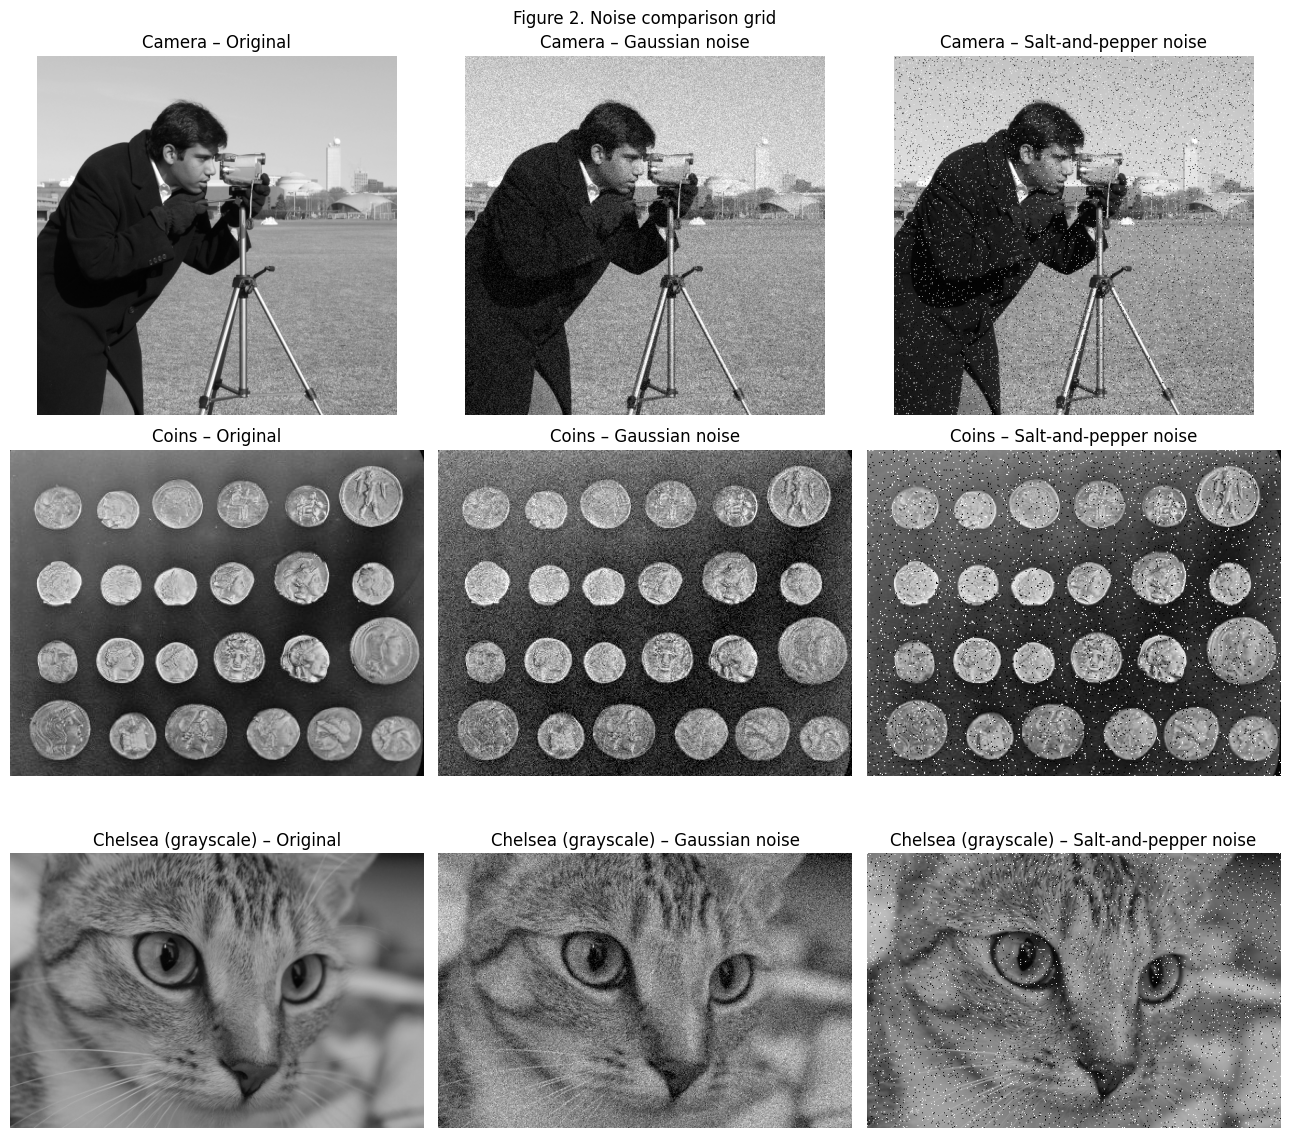

In [6]:
fig,axes=plt.subplots(3,3,figsize=(13,12))
for r,(name,clean) in enumerate(clean_images.items()):
    items=[(clean,f"{name} – Original"),
           (noisy_images[(name,"Gaussian noise")],f"{name} – Gaussian noise"),
           (noisy_images[(name,"Salt-and-pepper noise")],f"{name} – Salt-and-pepper noise")]
    for c,(img,title) in enumerate(items):
        axes[r,c].imshow(img,cmap="gray",vmin=0,vmax=255); axes[r,c].set_title(title); axes[r,c].axis("off")
plt.suptitle("Figure 2. Noise comparison grid"); plt.tight_layout(); plt.show()

## 5. Mean, Gaussian, and median filters
Allowed kernel sizes are odd: 3, 5, and 7. Mean and Gaussian smoothing kernels are normalized to sum to 1 (R3). Median uses the middle sorted neighbourhood value.

In [7]:
def mean_kernel(size):
    if size not in (3,5,7): raise ValueError("Use 3, 5, or 7.")
    return np.ones((size,size),dtype=np.float64)/(size*size)

def gaussian_kernel(size):
    if size not in (3,5,7): raise ValueError("Use 3, 5, or 7.")
    if size==3:
        v=np.array([1,2,1],dtype=np.float64)
        k=np.outer(v,v)/16
    else:
        v=cv2.getGaussianKernel(size,0,cv2.CV_64F).reshape(-1)
        k=np.outer(v,v); k=k/k.sum()
    return k.astype(np.float64)

for s in (3,5,7):
    print(f"{s}x{s}: mean sum={mean_kernel(s).sum():.12f}; Gaussian sum={gaussian_kernel(s).sum():.12f}")
    assert np.isclose(mean_kernel(s).sum(),1) and np.isclose(gaussian_kernel(s).sum(),1)

def apply_filters(img,size):
    if size not in (3,5,7): raise ValueError("Use odd size 3, 5, or 7.")
    mean_custom=to_uint8(conv2d_loop(img,mean_kernel(size)))
    mean_cv=cv2.blur(img,(size,size),borderType=cv2.BORDER_REFLECT_101)
    gaussian=cv2.GaussianBlur(img,(size,size),sigmaX=0,borderType=cv2.BORDER_REFLECT_101)
    p=size//2
    padded=np.pad(img,((p,p),(p,p)),mode="reflect")
    median=cv2.medianBlur(padded,size)[p:-p,p:-p]
    return {"Mean":mean_custom,"Mean (OpenCV)":mean_cv,"Gaussian":gaussian,"Median":median}

filtered={}
for (name,noise_name),noisy in noisy_images.items():
    for size in (3,5,7):
        filtered[(name,noise_name,size)]=apply_filters(noisy,size)
print("Completed combinations:",len(filtered))

3x3: mean sum=1.000000000000; Gaussian sum=1.000000000000
5x5: mean sum=1.000000000000; Gaussian sum=1.000000000000
7x7: mean sum=1.000000000000; Gaussian sum=1.000000000000


Completed combinations: 18


### 5.1 Custom mean versus OpenCV mean
The custom loop and `cv2.blur` must agree within rounding.

In [8]:
mean_diffs=[]
for key,outputs in filtered.items():
    d=np.abs(outputs["Mean"].astype(np.int16)-outputs["Mean (OpenCV)"].astype(np.int16))
    mean_diffs.append(int(d.max()))
print("Largest uint8 difference (custom mean vs cv2.blur):",max(mean_diffs))
print("Agreement within one level:",max(mean_diffs)<=1)

Largest uint8 difference (custom mean vs cv2.blur): 0
Agreement within one level: True


### 5.2 R1 and R2 checks
Every filtered output must be uint8, within 0–255, and the same shape as its input. Internal convolution uses float64.

In [9]:
checks=[]
for (name,noise_name,size),outputs in filtered.items():
    source=noisy_images[(name,noise_name)]
    for fname in ("Mean","Gaussian","Median"):
        a=outputs[fname]
        checks.append(a.dtype==np.uint8 and a.shape==source.shape and a.min()>=0 and a.max()<=255)
print("Number of outputs checked:",len(checks))
print("All R1/R2 checks passed:",all(checks))

Number of outputs checked: 54
All R1/R2 checks passed: True


### 5.3 Reject an even median kernel (R4)
The task asks to demonstrate that size 4 is invalid.

In [10]:
try:
    cv2.medianBlur(camera_original,4)
    even_rejected=False
    print("Unexpected: even kernel was accepted.")
except cv2.error as e:
    even_rejected=True
    print("Even kernel size 4 correctly rejected:",type(e).__name__)
assert even_rejected

Even kernel size 4 correctly rejected: error


## 6. 3×3 filter comparisons for every noisy image
Each result is displayed beside the noisy input and clean original. Judgements are made against the clean original (R6), not the noisy image.

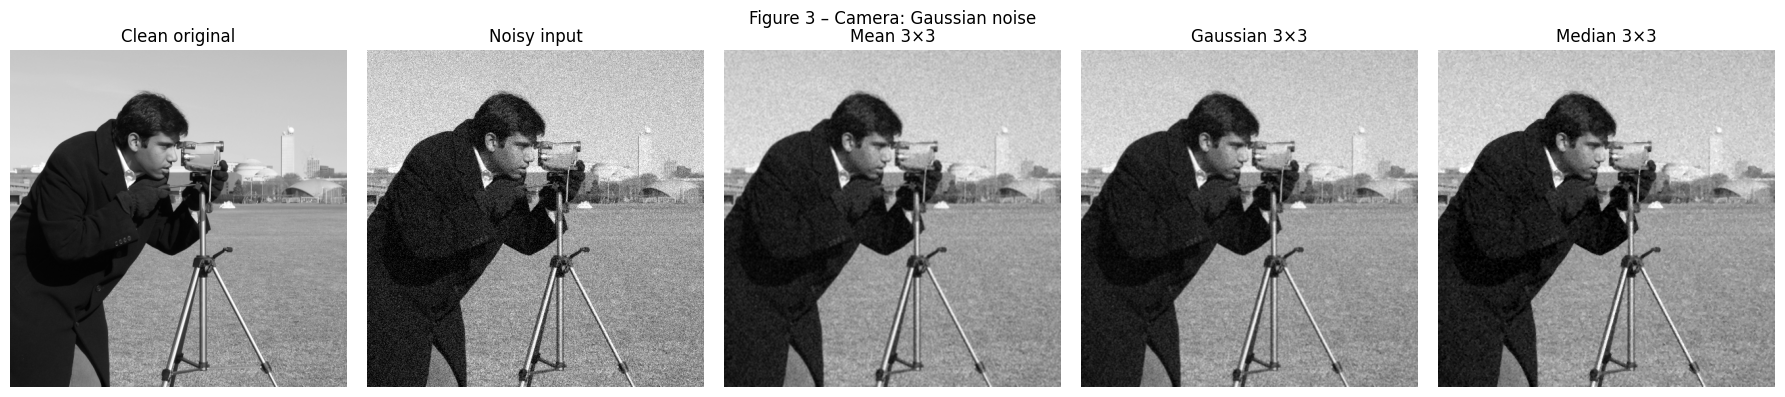

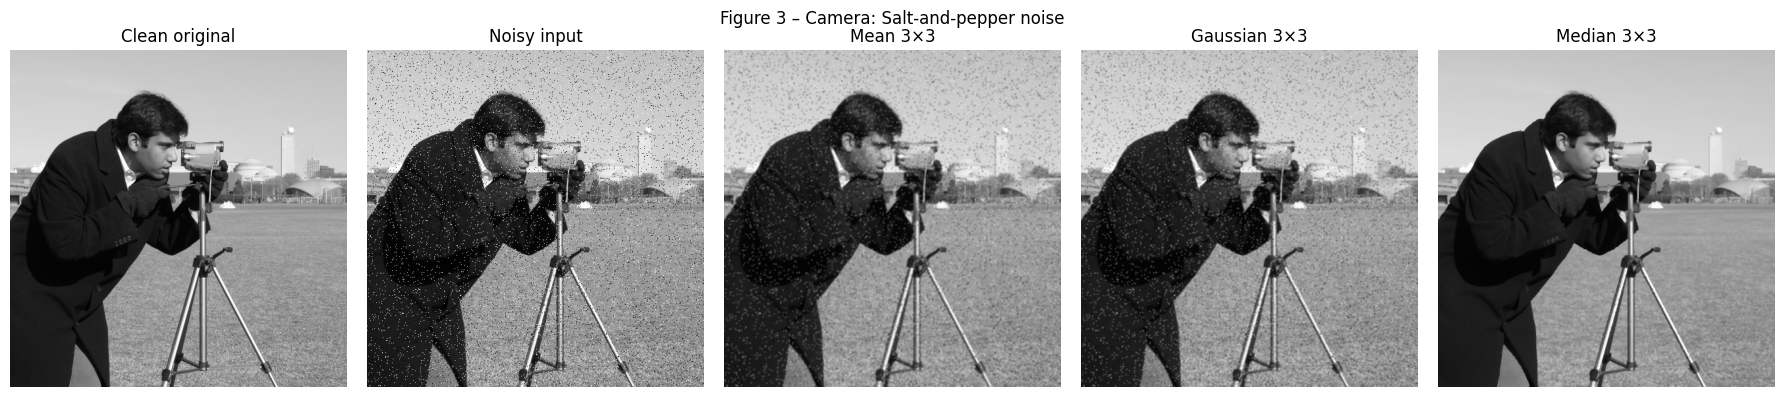

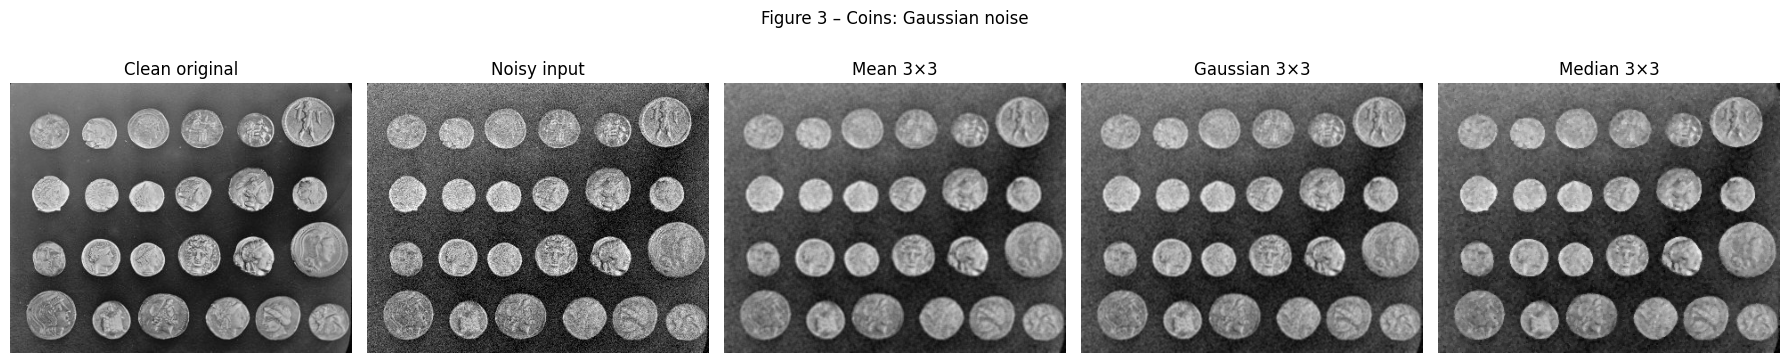

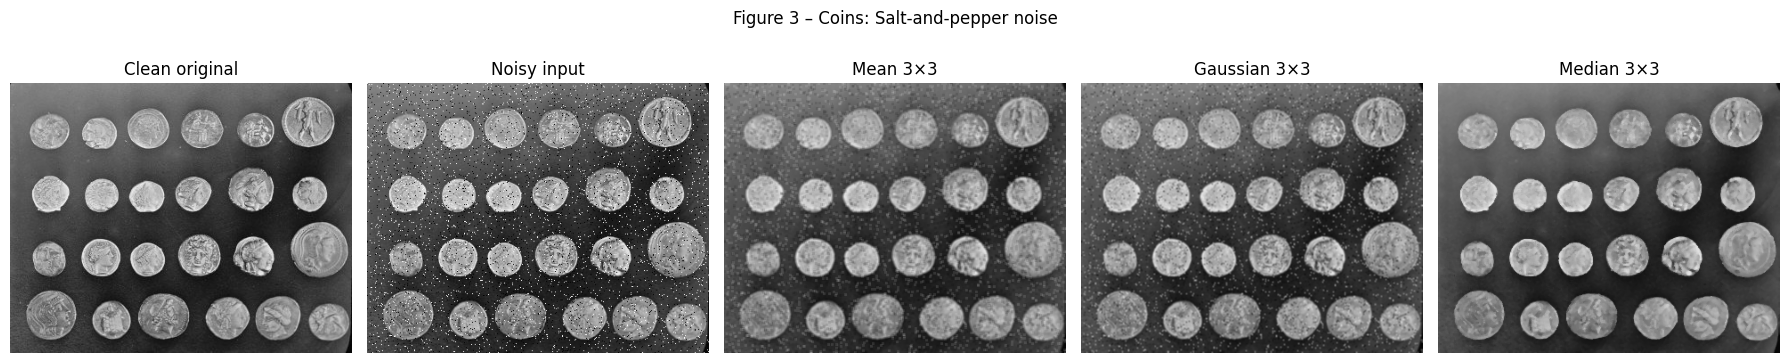

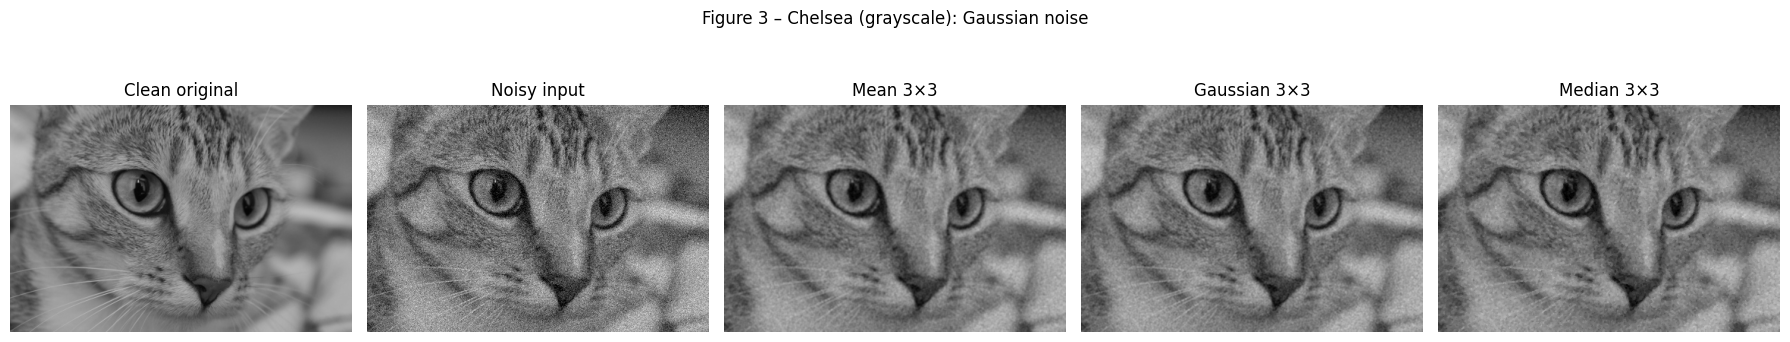

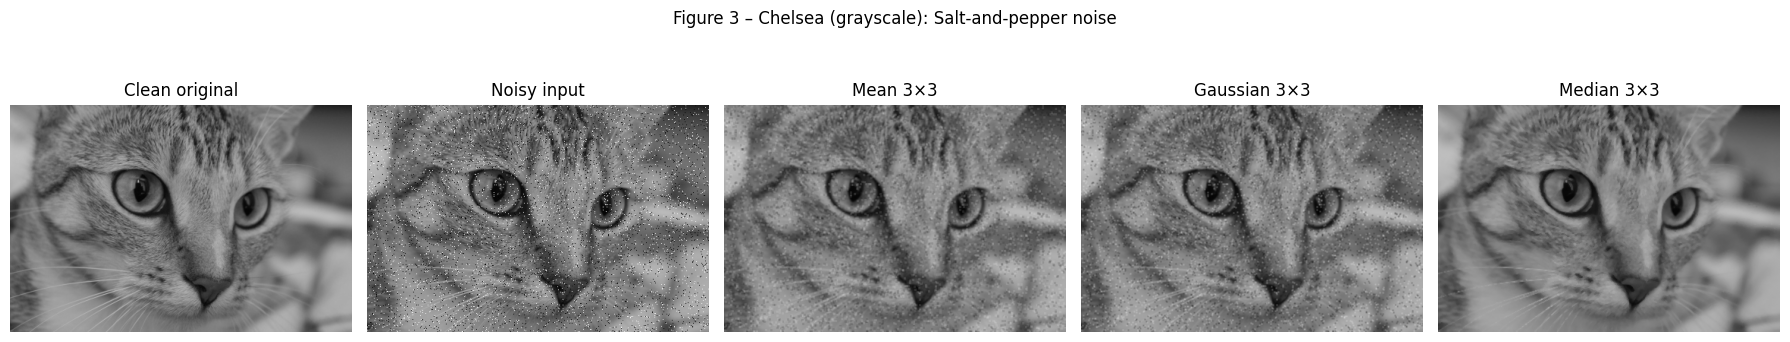

In [11]:
for (name,noise_name),noisy in noisy_images.items():
    outputs=filtered[(name,noise_name,3)]
    fig,axes=plt.subplots(1,5,figsize=(18,4))
    items=[(clean_images[name],"Clean original"),(noisy,"Noisy input"),
           (outputs["Mean"],"Mean 3×3"),(outputs["Gaussian"],"Gaussian 3×3"),
           (outputs["Median"],"Median 3×3")]
    for ax,(img,title) in zip(axes,items):
        ax.imshow(img,cmap="gray",vmin=0,vmax=255); ax.set_title(title); ax.axis("off")
    fig.suptitle(f"Figure 3 – {name}: {noise_name}"); plt.tight_layout(); plt.show()

## 7. Filter × kernel-size comparison grid
The selected difficult/noisy example is Coins with salt-and-pepper noise. The grid compares Mean, Gaussian, and Median at 3×3, 5×5, and 7×7.

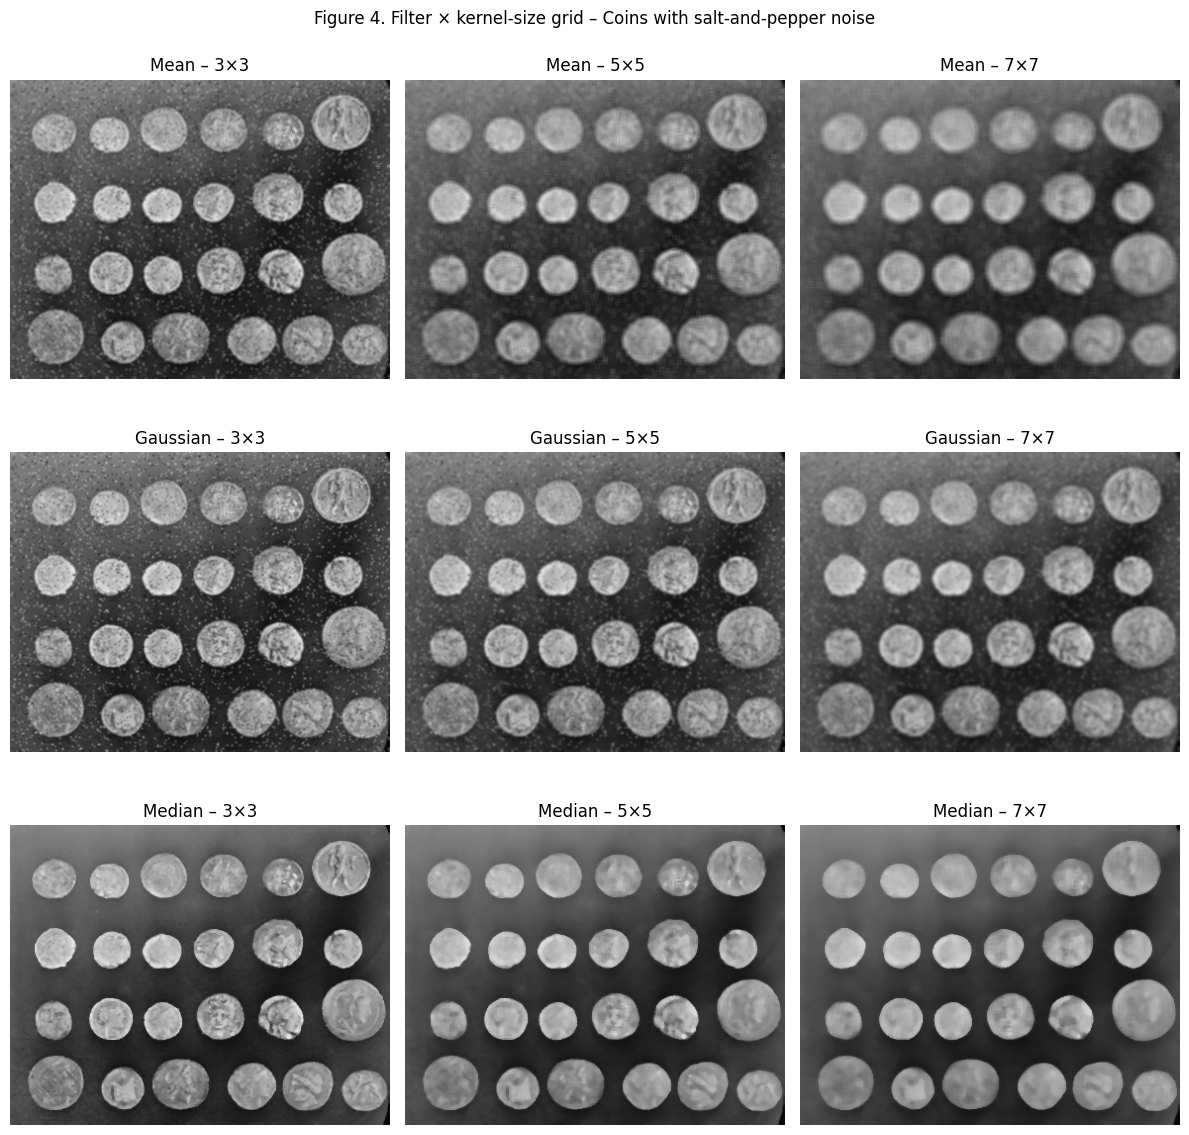

In [12]:
fig,axes=plt.subplots(3,3,figsize=(12,12))
for r,fname in enumerate(("Mean","Gaussian","Median")):
    for c,size in enumerate((3,5,7)):
        img=filtered[("Coins","Salt-and-pepper noise",size)][fname]
        axes[r,c].imshow(img,cmap="gray",vmin=0,vmax=255)
        axes[r,c].set_title(f"{fname} – {size}×{size}"); axes[r,c].axis("off")
plt.suptitle("Figure 4. Filter × kernel-size grid – Coins with salt-and-pepper noise")
plt.tight_layout(); plt.show()

## 8. Dry-run Exercise 1 – Spike response

Given neighbourhood:

\[
\begin{bmatrix}40&40&40\\40&255&40\\40&40&40\end{bmatrix}
\]

**Mean:** Eight pixels are 40 and one is 255.

\[
\text{Sum}=8(40)+255=575,\qquad \text{Mean}=575/9=63.8889\approx64
\]

**Gaussian:** The 3×3 kernel is:

\[
\frac{1}{16}\begin{bmatrix}1&2&1\\2&4&2\\1&2&1\end{bmatrix}
\]

The centre weight is 4 and the other weights sum to 12.

\[
\text{Weighted sum}=255(4)+40(12)=1020+480=1500
\]
\[
\text{Output}=1500/16=93.75\approx94
\]

**Median:** Sorted values are `[40,40,40,40,40,40,40,40,255]`. The fifth (middle) value is **40**.

### Code verification

In [13]:
spike=np.array([[40,40,40],[40,255,40],[40,40,40]],dtype=np.uint8)
m=conv2d_loop(spike,mean_kernel(3))[1,1]
g=conv2d_loop(spike,gaussian_kernel(3))[1,1]
med=float(np.median(spike))
print("Mean:",m,"Gaussian:",g,"Median:",med)
assert np.isclose(m,575/9) and np.isclose(g,1500/16) and med==40

Mean: 63.88888888888889 Gaussian: 93.75 Median: 40.0


## 9. Dry-run Exercise 2 – Reflect padding at a corner

Given image:

\[
\begin{bmatrix}10&20&30\\40&50&60\\70&80&90\end{bmatrix}
\]

Using NumPy `mode="reflect"`, the padded 3×3 neighbourhood used for the top-left output pixel `(0,0)` is:

\[
\begin{bmatrix}50&40&50\\20&10&20\\50&40&50\end{bmatrix}
\]

\[
\text{Sum}=50+40+50+20+10+20+50+40+50=330
\]
\[
\text{Mean}=330/9=36.6667\approx37
\]

### Code verification

In [14]:
corner=np.array([[10,20,30],[40,50,60],[70,80,90]],dtype=np.uint8)
padded=np.pad(corner.astype(np.float64),1,mode="reflect")
patch=padded[:3,:3]
value=conv2d_loop(corner,mean_kernel(3))[0,0]
print("Padded neighbourhood:\n",patch)
print("Sum:",patch.sum(),"Mean output:",value)
assert np.array_equal(patch,np.array([[50,40,50],[20,10,20],[50,40,50]],dtype=float))
assert np.isclose(value,330/9)

Padded neighbourhood:
 [[50. 40. 50.]
 [20. 10. 20.]
 [50. 40. 50.]]
Sum: 330.0 Mean output: 36.66666666666667


## 10. Observations and comparisons (R6)

The following comparisons refer to the labelled figures and use the clean original as the reference.

1. **Gaussian noise – best and worst:** The Gaussian filter generally gives a balanced reduction of random grain while retaining natural transitions. Mean also reduces noise but can flatten edges more. Median is usually less suitable for widespread Gaussian noise because it is mainly effective against isolated outliers. Inspect smooth background areas in Figure 3 for Camera.
2. **Salt-and-pepper noise – best and why the other two fail:** Median is best in Figure 3 for Coins because isolated 0 and 255 pixels are outliers; the middle sorted value rejects them. Mean and Gaussian include those extreme values in their weighted sums, so bright and dark specks influence nearby output pixels. Compare coin-face regions in Figure 3 and Figure 4.
3. **Mean versus Gaussian on a sharp edge:** At a coin/background boundary in Figure 3, both soften the edge. Gaussian gives greater weight to nearby centre pixels and usually creates a smoother transition. Mean gives equal weight to every pixel in the window and produces more uniform blurring.
4. **Fine detail at 7×7:** Figure 4 shows that the larger neighbourhood removes small variations, but fine coin markings and narrow boundaries become blurred or disappear. The 7×7 output is smoother but loses more detail than 3×3.
5. **Why kernel size must be odd:** An odd-sized kernel has one central pixel, allowing it to be centred on the input pixel with symmetric padding. An even-sized kernel has no single centre, making alignment ambiguous. The median operation in this task also explicitly rejects even sizes.

Visual outcomes can vary by image region; the answers above identify the specific labelled comparisons used.

## 11. Viva preparation – two brief answers

**Q1. What is a kernel?**  
A kernel is a small matrix of numbers (weights) moved over an image. It calculates a new pixel from the pixels in its neighbourhood. A 3×3 mean kernel, for example, has nine weights equal to 1/9.

**Q2. Why does the median remove a 255 spike but the mean does not?**  
Median sorts the neighbourhood and selects its middle value. One extreme 255 value usually does not change the middle value. Mean includes every value in its sum, so 255 increases the average.

In [15]:
print("R1/R2 output shape, dtype and range:", "PASS" if all(checks) else "FAIL")
print("R3 normalized mean/Gaussian kernels:",
      "PASS" if all(np.isclose(mean_kernel(s).sum(),1) and np.isclose(gaussian_kernel(s).sum(),1) for s in (3,5,7)) else "FAIL")
print("R4 even median kernel rejection:", "PASS" if even_rejected else "FAIL")
print("R5 Gaussian reproducibility:",
      "PASS" if np.array_equal(add_gaussian_noise(camera_original,20,5),add_gaussian_noise(camera_original,20,5)) else "FAIL")
print("R5 salt-pepper reproducibility:",
      "PASS" if np.array_equal(add_salt_pepper(camera_original,.05,5),add_salt_pepper(camera_original,.05,5)) else "FAIL")
print("Convolution/OpenCV largest absolute difference:",largest_difference)
print("Mean/OpenCV largest uint8 difference:",max(mean_diffs))

R1/R2 output shape, dtype and range: PASS
R3 normalized mean/Gaussian kernels: PASS
R4 even median kernel rejection: PASS
R5 Gaussian reproducibility: PASS
R5 salt-pepper reproducibility: PASS
Convolution/OpenCV largest absolute difference: 0.0
Mean/OpenCV largest uint8 difference: 0
